In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

SEED = 987

DIR_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

df = listings.copy()

In [3]:
off_market.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3974 entries, 0 to 3973
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   ml_num           3974 non-null   object        
 1   date_listed      3974 non-null   datetime64[us]
 2   house_type_name  3974 non-null   object        
 3   house_style      3974 non-null   object        
 4   bedrooms         3974 non-null   int64         
 5   washrooms        3974 non-null   int64         
 6   parking_total    3974 non-null   int64         
 7   garage           3974 non-null   float64       
 8   house_area       3974 non-null   object        
 9   lot_front        1825 non-null   float64       
 10  lot_depth        1825 non-null   float64       
 11  municipality     3974 non-null   object        
 12  community        3974 non-null   object        
 13  latitude         3974 non-null   float64       
 14  longitude        3974 non-null   float64

In [4]:
from notebooks.xxbonkxx.models import baseline_features

df["month"] = baseline_features.make_months(listings)
df["day"] = baseline_features.make_days(listings)
df["year"] = baseline_features.make_years(listings)
df["is_apartment"] = baseline_features.make_is_apartment(listings)

off_market["house_area"] = baseline_features.square_feet(off_market["house_area"])

In [5]:
def get_ranges_house_area(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    is_range = df["house_area"].astype(str).str.fullmatch(r"\d+\s*-\s*\d+")
    return df[is_range].copy(), df[~is_range].copy()

In [17]:
df_ranges, df_no_ranges = get_ranges_house_area(df)
df_no_ranges["house_area"] = pd.to_numeric(df_no_ranges["house_area"], errors="coerce")

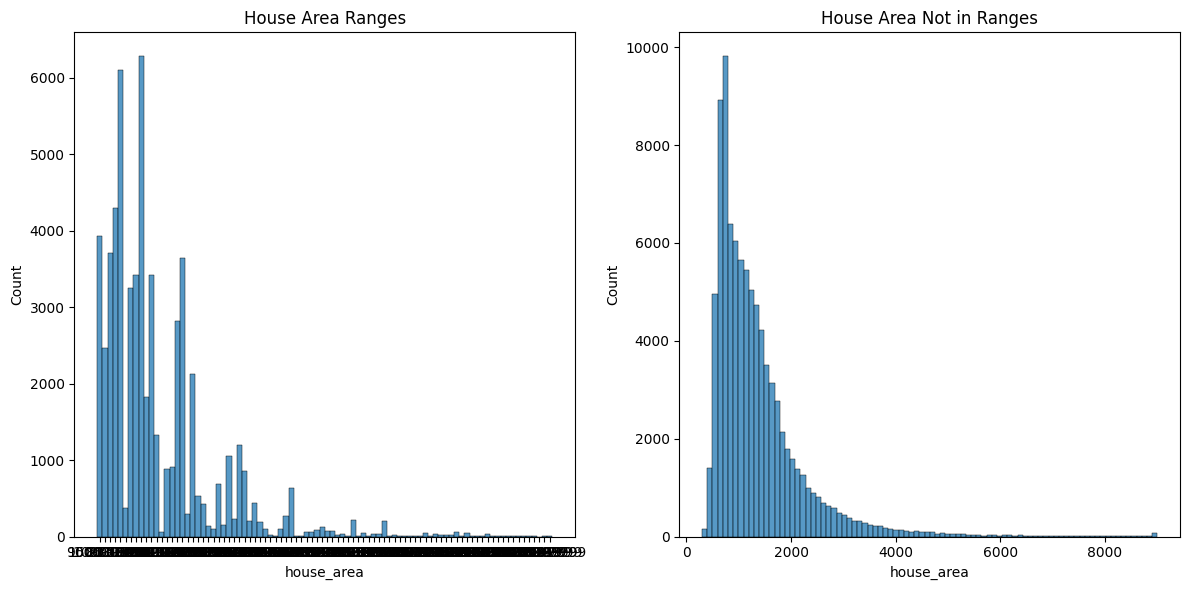

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
sns.histplot(data=df_ranges, x="house_area", ax=axes[0])
axes[0].set_title("House Area Ranges")
sns.histplot(data=df_no_ranges, x="house_area", ax=axes[1], bins=88)
axes[1].set_title("House Area Not in Ranges")
plt.tight_layout()
plt.show()


In [19]:
len(df_ranges), len(df_no_ranges)

(60031, 89969)

In [20]:
display(df_ranges.describe())
display(df_no_ranges.describe())

,sold_price,list_price,date_listed,date_sold,days_on_market,bedrooms,washrooms,parking_total,garage,lot_front,lot_depth,latitude,longitude,external_avm_estimate,external_avm_estimate_date,month,day,year,is_apartment
count,6.003100e+04,6.003100e+04,60031,60031,60031.000000,60031.000000,60031.000000,60031.000000,60031.000000,25159.000000,25159.000000,60031.000000,60031.000000,5.952600e+04,60031,60031.000000,60031.000000,60031.000000,60031.000000
mean,1.076634e+06,1.077616e+06,2023-04-19 03:41:30.093451,2023-05-11 11:51:38.419150,22.340374,2.347004,2.164815,1.856457,0.415152,36.336077,119.355439,43.643239,-79.378679,1.090852e+06,2023-09-24 11:02:16.429511,5.944079,838.153821,2022.845347,0.575786
min,2.059000e+05,2.059000e+05,2020-03-12 00:00:00,2021-01-01 00:00:00,0.000000,0.000000,1.000000,0.000000,0.000000,10.000000,40.000000,43.490267,-79.597572,1.985000e+05,2020-12-03 00:00:00,1.000000,-295.000000,2020.000000,0.000000
25%,6.251000e+05,6.333000e+05,2021-10-26 00:00:00,2021-11-10 00:00:00,6.000000,1.000000,1.000000,1.000000,0.000000,22.940000,98.920000,43.600761,-79.445120,6.282000e+05,2022-04-05 00:00:00,3.000000,298.000000,2021.000000,0.000000
50%,8.597000e+05,8.621000e+05,2023-03-16 00:00:00,2023-04-04 00:00:00,12.000000,2.000000,2.000000,1.000000,0.000000,32.450000,116.740000,43.641793,-79.391701,8.638000e+05,2023-07-22 00:00:00,5.000000,804.000000,2023.000000,1.000000
75%,1.245600e+06,1.239500e+06,2024-08-25 00:00:00,2024-09-29 00:00:00,26.000000,3.000000,3.000000,3.000000,1.000000,46.045000,136.830000,43.679576,-79.314206,1.264100e+06,2025-02-18 00:00:00,9.000000,1332.000000,2024.000000,1.000000
max,2.314560e+07,2.127690e+07,2026-05-29 00:00:00,2026-05-31 00:00:00,320.000000,6.000000,6.000000,6.000000,6.000000,150.000000,300.000000,43.840579,-79.070793,1.819060e+07,2027-06-29 00:00:00,12.000000,1974.000000,2026.000000,1.000000
std,8.073634e+05,8.052084e+05,NaN,NaN,31.899788,1.105425,1.112386,1.647416,0.715544,17.684890,30.623722,0.054412,0.100205,8.367313e+05,NaN,3.266566,584.211558,1.602774,0.494227


,sold_price,list_price,date_listed,date_sold,days_on_market,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,latitude,longitude,external_avm_estimate,external_avm_estimate_date,month,day,year,is_apartment
count,8.996900e+04,8.996900e+04,89969,89969,89969.000000,89969.000000,89969.000000,89969.000000,89969.000000,89969.000000,37578.000000,37578.000000,89969.000000,89969.000000,8.916800e+04,89969,89969.000000,89969.000000,89969.000000,89969.000000
mean,1.072104e+06,1.072429e+06,2023-04-14 20:53:40.789382,2023-05-07 01:50:01.313785,22.205793,2.338116,2.153975,1.851338,0.409663,1356.984661,36.324893,119.320344,43.643595,-79.378638,1.076333e+06,2023-09-20 12:41:10.450932,5.943069,833.870611,2022.833809,0.577632
min,1.726000e+05,1.618000e+05,2020-02-19 00:00:00,2021-01-01 00:00:00,0.000000,0.000000,1.000000,0.000000,0.000000,300.000000,10.000000,40.000000,43.490027,-79.593971,2.078000e+05,2020-12-04 00:00:00,1.000000,-317.000000,2020.000000,0.000000
25%,6.226000e+05,6.307000e+05,2021-10-24 00:00:00,2021-11-07 00:00:00,6.000000,1.000000,1.000000,1.000000,0.000000,760.000000,22.930000,98.820000,43.601064,-79.446436,6.134000e+05,2022-04-04 00:00:00,3.000000,296.000000,2021.000000,0.000000
50%,8.546000e+05,8.579000e+05,2023-03-09 00:00:00,2023-03-27 00:00:00,12.000000,2.000000,2.000000,1.000000,0.000000,1120.000000,32.580000,116.600000,43.642178,-79.391630,8.502000e+05,2023-07-14 00:00:00,5.000000,797.000000,2023.000000,1.000000
75%,1.236000e+06,1.229800e+06,2024-08-23 00:00:00,2024-09-28 00:00:00,26.000000,3.000000,3.000000,3.000000,1.000000,1624.000000,46.080000,136.990000,43.679698,-79.313266,1.242400e+06,2025-02-17 00:00:00,9.000000,1330.000000,2024.000000,1.000000
max,3.000000e+07,2.807800e+07,2026-05-29 00:00:00,2026-05-31 00:00:00,320.000000,6.000000,6.000000,6.000000,6.000000,9000.000000,150.000000,300.000000,43.843841,-79.073930,2.807060e+07,2027-06-30 00:00:00,12.000000,1974.000000,2026.000000,1.000000
std,8.159585e+05,8.139624e+05,NaN,NaN,31.445682,1.106796,1.106924,1.647070,0.711573,897.527455,17.558476,30.741895,0.054338,0.100853,8.428596e+05,NaN,3.266837,584.265267,1.600809,0.493939


In [ ]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
import pandas as pd

def compare_means(df1, df2):
    results = []

    for col in df1.columns.intersection(df2.columns):
        if not pd.api.types.is_numeric_dtype(df1[col]):
            continue

        a = df1[col].dropna()
        b = df2[col].dropna()

        stat, p_value = ttest_ind(a, b, equal_var=False)

        results.append({
            "feature": col,
            "mean_1": a.mean(),
            "mean_2": b.mean(),
            "mean_difference": a.mean() - b.mean(),
            "p_value": p_value,
        })

    results = pd.DataFrame(results)

    # Correct for multiple hypothesis tests
    if not results.empty:
        results["adjusted_p_value"] = multipletests(
            results["p_value"], method="fdr_bh"
        )[1]
        results["significant"] = results["adjusted_p_value"] < 0.05

    return results.sort_values("adjusted_p_value")

In [28]:
compare_means(df_ranges, df_no_ranges)

,feature,mean_1,mean_2,mean_difference,p_value,adjusted_p_value,significant
11,external_avm_estimate,1.090852e+06,1.076333e+06,14519.313283,0.001080,0.017281,True
1,list_price,1.077616e+06,1.072429e+06,5187.549952,0.223542,0.447084,False
6,garage,4.151522e-01,4.096633e-01,0.005489,0.144621,0.447084,False
3,bedrooms,2.347004e+00,2.338116e+00,0.008888,0.127299,0.447084,False
13,day,8.381538e+02,8.338706e+02,4.283210,0.164184,0.447084,False
14,year,2.022845e+03,2.022834e+03,0.011537,0.171767,0.447084,False
9,latitude,4.364324e+01,4.364360e+01,-0.000356,0.213549,0.447084,False
4,washrooms,2.164815e+00,2.153975e+00,0.010840,0.063932,0.447084,False
0,sold_price,1.076634e+06,1.072104e+06,4529.609926,0.289122,0.513994,False
2,days_on_market,2.234037e+01,2.220579e+01,0.134581,0.420758,0.673212,False


In [31]:
df_ranges["house_area_num"] = baseline_features.square_feet(df_ranges["house_area"])
stat, p_value = ttest_ind(df_ranges["house_area_num"], df_no_ranges["house_area"], equal_var=False)
print(f"T-test result: stat={stat}, p-value={p_value}")
print(f"Mean house area (ranges): {df_ranges['house_area_num'].mean()}")
print(f"Mean house area (no ranges): {df_no_ranges['house_area'].mean()}")

T-test result: stat=12.229601914401641, p-value=2.2572464767925555e-34
Mean house area (ranges): 1414.885384218154
Mean house area (no ranges): 1356.9846613833654


okei this is probably not a good thing. In the case that there actually is no difference in the mean house area, then our model isn't fitting the stuff properly. In the case that there is an actual difference. Well we'll have to find a way to adjust for it.

potential solutions:
1. we can add a new feature for area was range.

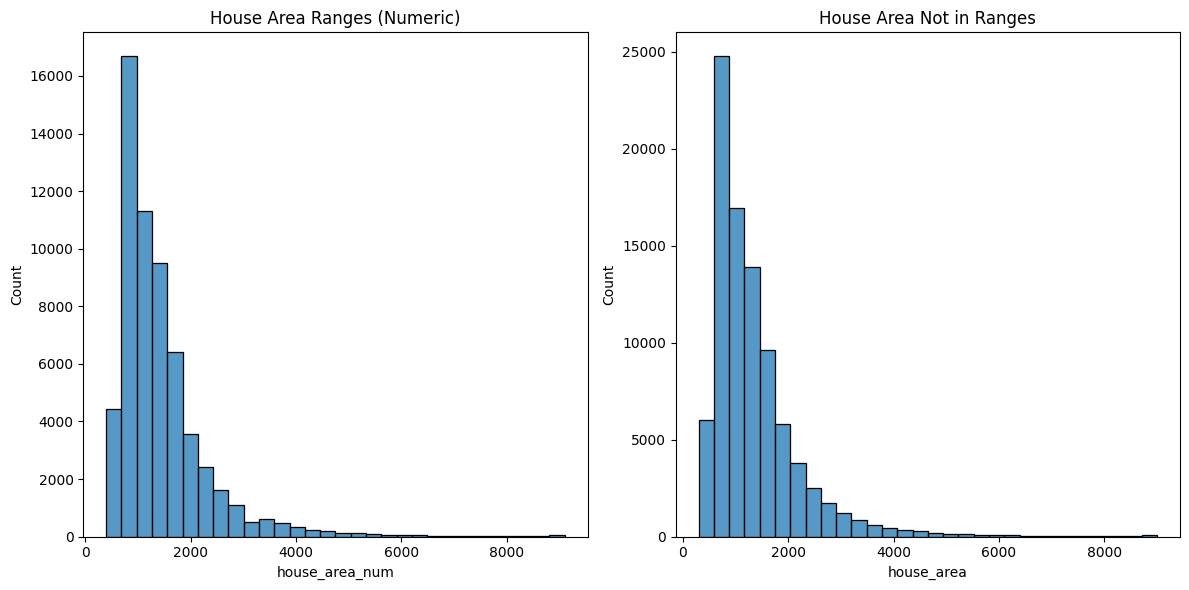

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
sns.histplot(data=df_ranges, x="house_area_num", ax=axes[0], bins=30)
axes[0].set_title("House Area Ranges (Numeric)")
sns.histplot(data=df_no_ranges, x="house_area", ax=axes[1], bins=30)
axes[1].set_title("House Area Not in Ranges")
plt.tight_layout()
plt.show()

<Axes: xlabel='house_area', ylabel='Count'>

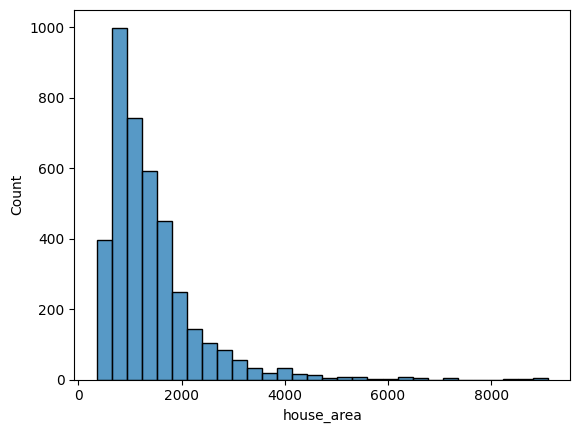

In [35]:
sns.histplot(off_market["house_area"], bins=30)